# E-commerce Customer Segmentation – Sample Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
An online store wants to **group its customers into segments** (best, regular, at risk, low value) so the marketing team can give the right offer to each group.

**Questions we will answer**
1. What is the overall spending behaviour of customers?
2. Do recent purchases and number of orders affect total spend?
3. Does spending differ by city tier, gender, device or acquisition channel?
4. Which customers are at risk of leaving?

> The dataset is **synthetic** (computer-generated) and contains no real customer data.

## 2. Import libraries

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [27]:
df = pd.read_csv('../data/raw/ecommerce_customers.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 12)


,Customer_ID,Gender,Age,City_Tier,Preferred_Device,Acquisition_Channel,Last_Purchase_Days_Ago,Total_Orders,Total_Spend,Discount_Orders_Pct,Return_Rate_Pct,Avg_Rating_Given
0,C10001,Female,35.0,Tier 1,Desktop,Paid Ads,113.0,5,4976,50.3,4.0,3.6
1,C10002,Male,37.0,Tier 3,Mobile,Referral,12.0,2,1332,27.4,9.5,3.6
2,C10003,Female,24.0,Tier 2,Desktop,Organic,83.0,3,3049,49.7,0.0,4.0
3,C10004,Female,32.0,Tier 1,Mobile,Email,265.0,7,6399,9.8,12.2,4.2
4,C10005,Male,18.0,Tier 2,Mobile,Paid Ads,20.0,20,26678,17.7,2.3,4.3


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer_ID             255 non-null    str    
 1   Gender                  255 non-null    str    
 2   Age                     250 non-null    float64
 3   City_Tier               255 non-null    str    
 4   Preferred_Device        255 non-null    str    
 5   Acquisition_Channel     255 non-null    str    
 6   Last_Purchase_Days_Ago  252 non-null    float64
 7   Total_Orders            255 non-null    int64  
 8   Total_Spend             255 non-null    int64  
 9   Discount_Orders_Pct     252 non-null    float64
 10  Return_Rate_Pct         255 non-null    float64
 11  Avg_Rating_Given        248 non-null    float64
dtypes: float64(5), int64(2), str(5)
memory usage: 24.0 KB


In [29]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Age                       5
Last_Purchase_Days_Ago    3
Discount_Orders_Pct       3
Avg_Rating_Given          7
dtype: int64

Duplicate rows: 0


,Age,Last_Purchase_Days_Ago,Total_Orders,Total_Spend,Discount_Orders_Pct,Return_Rate_Pct,Avg_Rating_Given
count,250.0,252.0,255.0,255.0,252.0,255.0,248.0
mean,33.3,70.3,8.3,11300.7,35.1,7.9,4.0
std,11.2,78.2,7.6,14807.6,17.5,5.5,0.6
min,18.0,1.0,1.0,-2500.0,0.0,0.0,1.4
25%,27.0,14.0,3.0,2193.0,22.4,3.8,3.6
50%,33.0,31.5,6.0,5178.0,35.6,7.6,4.0
75%,39.0,91.5,11.5,14557.0,46.1,11.6,4.4
max,150.0,343.0,37.0,92930.0,84.2,26.0,5.0


**What we found:** some missing values, duplicate rows, inconsistent text in `Gender` and `City_Tier` (e.g. `male`, `FEMALE`, `tier 1`), a negative `Total_Spend` and an impossible `Age` of 150. We clean these next.

## 4. Clean the data

In [30]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text
for c in ['Gender','City_Tier']:
    clean[c] = clean[c].str.strip().str.title()
# 3. Fix impossible values (spend cannot be negative, age cannot be above 100)
clean.loc[clean['Total_Spend']<0,'Total_Spend'] = np.nan
clean.loc[clean['Age']>100,'Age'] = np.nan
# 4. Fill missing numbers with the median (robust to outliers)
num_cols = ['Age','Last_Purchase_Days_Ago','Total_Orders','Total_Spend','Discount_Orders_Pct','Return_Rate_Pct','Avg_Rating_Given']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 255 | Missing values left: 0


## 5. Create new columns (feature engineering)
**RFM** = **R**ecency (days since last order), **F**requency (number of orders), **M**onetary (total spend). Each gets a score from 1 (low) to 3 (high); then customers are grouped into segments.

In [31]:
clean['Avg_Order_Value'] = (clean['Total_Spend']/clean['Total_Orders']).round(0)
# Scores 1-3 (for Recency, fewer days is better so labels are reversed)
clean['R_Score'] = pd.qcut(clean['Last_Purchase_Days_Ago'],3,labels=[3,2,1]).astype(int)
clean['F_Score'] = pd.qcut(clean['Total_Orders'].rank(method='first'),3,labels=[1,2,3]).astype(int)
clean['M_Score'] = pd.qcut(clean['Total_Spend'],3,labels=[1,2,3]).astype(int)
clean['RFM_Total'] = clean['R_Score']+clean['F_Score']+clean['M_Score']
def segment(row):
    if row['RFM_Total']>=8: return 'Best Customers'
    if row['RFM_Total']>=6: return 'Regular Customers'
    if row['R_Score']==1: return 'At Risk'
    return 'Low Value'
clean['Segment'] = clean.apply(segment,axis=1)
clean['Recency_Band'] = pd.cut(clean['Last_Purchase_Days_Ago'],[0,30,90,180,400],labels=['<30 days','30-90 days','90-180 days','>180 days'])
clean[['Customer_ID','R_Score','F_Score','M_Score','RFM_Total','Segment']].head()

,Customer_ID,R_Score,F_Score,M_Score,RFM_Total,Segment
0,C10001,1,2,2,5,At Risk
1,C10002,3,1,1,5,Low Value
2,C10003,1,1,2,4,At Risk
3,C10004,1,2,2,5,At Risk
4,C10005,2,3,3,8,Best Customers


## 6. Exploratory data analysis (EDA)

### Q1. Overall spending behaviour

count      255.0
mean     11330.8
std      14787.2
min        204.0
25%       2213.0
50%       5185.5
75%      14557.0
max      92930.0
Name: Total_Spend, dtype: float64


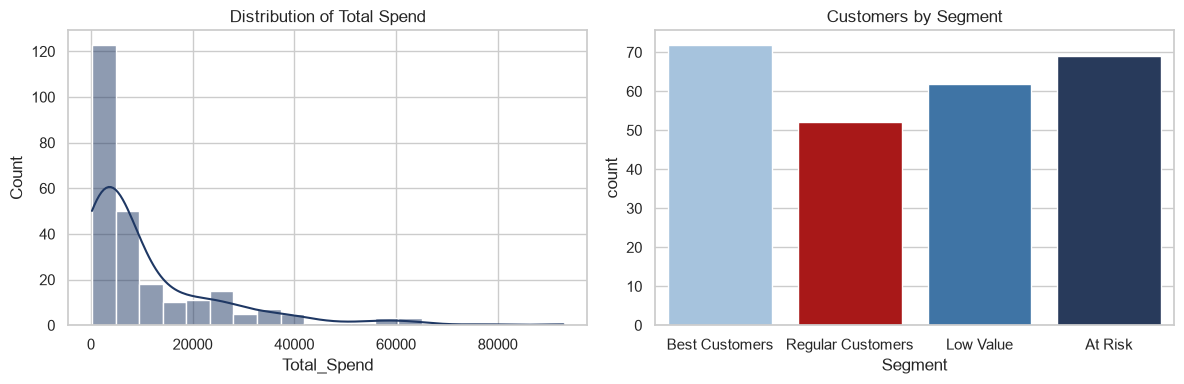

In [32]:
print(clean['Total_Spend'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Total_Spend'],bins=20,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Total Spend')
order=['Best Customers','Regular Customers','Low Value','At Risk']
sns.countplot(data=clean,x='Segment',hue='Segment',legend=False,order=order,palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1]);ax[1].set_title('Customers by Segment')
plt.tight_layout();plt.savefig('../images/01_overall_spending.png');plt.show()

In [33]:
seg = clean.groupby('Segment').agg(Customers=('Customer_ID','count'),Avg_Days_Since_Purchase=('Last_Purchase_Days_Ago','mean'),Avg_Orders=('Total_Orders','mean'),Avg_Spend=('Total_Spend','mean'),Total_Revenue=('Total_Spend','sum')).round(0).loc[order]
seg['Pct_Customers'] = (seg['Customers']/seg['Customers'].sum()*100).round(1)
seg['Pct_Revenue'] = (seg['Total_Revenue']/seg['Total_Revenue'].sum()*100).round(1)
seg

,Customers,Avg_Days_Since_Purchase,Avg_Orders,Avg_Spend,Total_Revenue,Pct_Customers,Pct_Revenue
Segment,,,,,,,
Best Customers,72,20.0,19.0,29591.0,2130560.0,28.2,73.7
Regular Customers,52,83.0,6.0,7087.0,368501.0,20.4,12.8
Low Value,62,20.0,2.0,1615.0,100106.0,24.3,3.5
At Risk,69,156.0,5.0,4206.0,290188.0,27.1,10.0


### Q2. Do recent purchases and number of orders affect total spend?

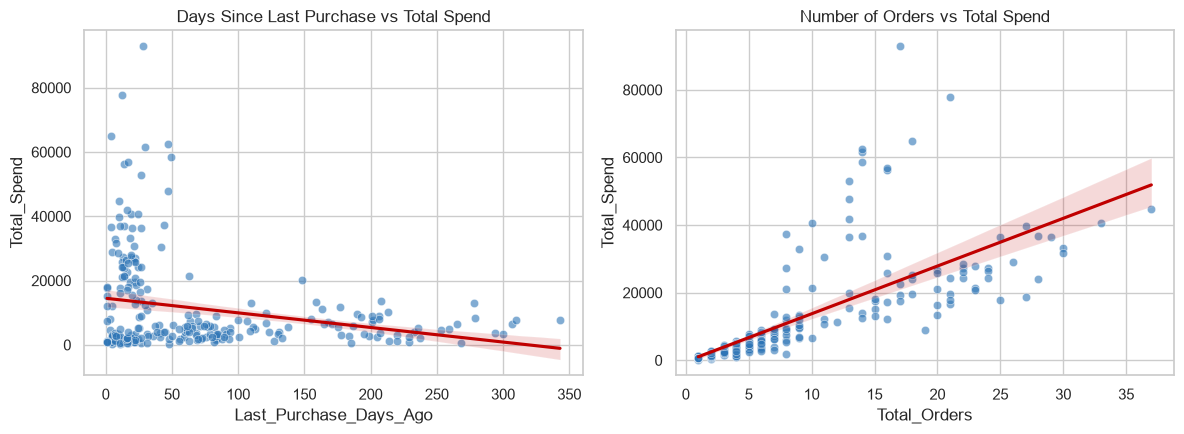

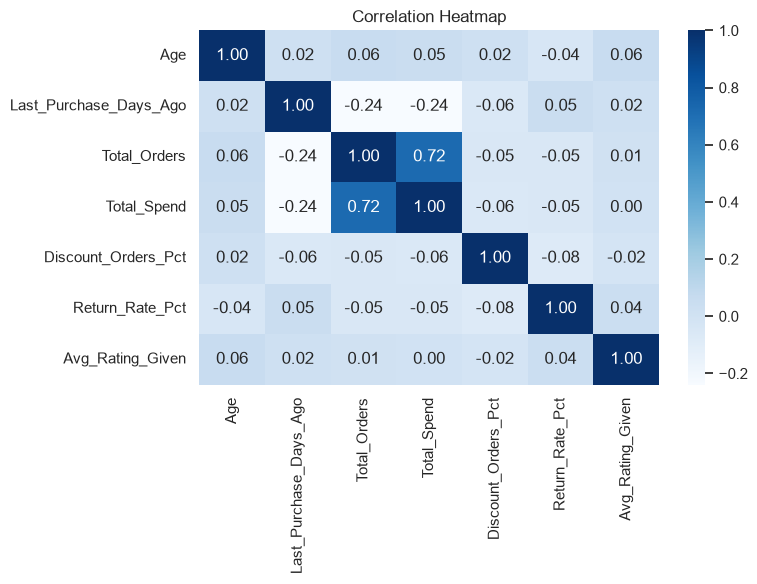

In [34]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Last_Purchase_Days_Ago',y='Total_Spend',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Last_Purchase_Days_Ago',y='Total_Spend',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Days Since Last Purchase vs Total Spend')
sns.scatterplot(data=clean,x='Total_Orders',y='Total_Spend',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Total_Orders',y='Total_Spend',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Number of Orders vs Total Spend')
plt.tight_layout();plt.savefig('../images/02_recency_frequency.png');plt.show()
plt.figure(figsize=(8,6))
sns.heatmap(clean[num_cols].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/03_correlation.png');plt.show()

In [35]:
print(clean.groupby('Recency_Band',observed=True)['Total_Spend'].agg(['count','mean']).round(1))

              count     mean
Recency_Band                
<30 days        125  15883.5
30-90 days       66   7912.9
90-180 days      29   6540.4
>180 days        35   5485.6


### Q3. Does spending differ by city tier, gender, device or acquisition channel?

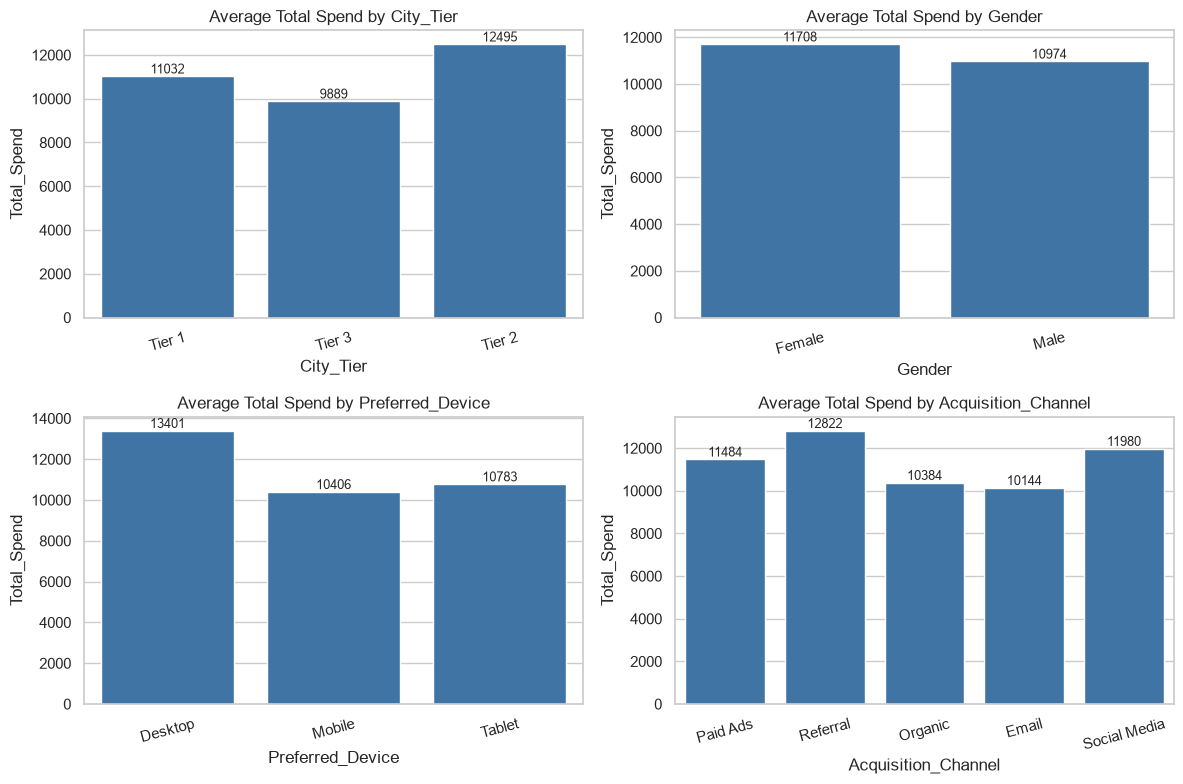

In [36]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['City_Tier','Gender','Preferred_Device','Acquisition_Channel']):
    sns.barplot(data=clean,x=col,y='Total_Spend',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Total Spend by {col}')
    a.tick_params(axis='x',rotation=15)
    for p in a.patches:a.annotate(f'{p.get_height():.0f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.savefig('../images/04_group_comparison.png');plt.show()

### Q4. Which customers are at risk?

In [37]:
risk = clean[clean['Segment']=='At Risk'].sort_values('Total_Spend',ascending=False)
print(f'{len(risk)} customers ({len(risk)/len(clean):.1%}) are At Risk')
print('Average days since last purchase of At Risk customers:', round(risk['Last_Purchase_Days_Ago'].mean()),'vs overall', round(clean['Last_Purchase_Days_Ago'].mean()))
print('Past spend of At Risk customers: Rs.', int(risk['Total_Spend'].sum()))
risk[['Customer_ID','City_Tier','Last_Purchase_Days_Ago','Total_Orders','Total_Spend']].head(10)

69 customers (27.1%) are At Risk
Average days since last purchase of At Risk customers: 156 vs overall 70
Past spend of At Risk customers: Rs. 290187


,Customer_ID,City_Tier,Last_Purchase_Days_Ago,Total_Orders,Total_Spend
140,C10141,Tier 3,206.0,6,8859.0
150,C10151,Tier 1,83.0,7,8833.0
171,C10172,Tier 2,193.0,7,8610.0
246,C10247,Tier 2,279.0,6,8323.0
143,C10144,Tier 1,155.0,7,8167.0
211,C10212,Tier 2,206.0,6,8041.0
182,C10183,Tier 2,202.0,6,7882.0
119,C10120,Tier 1,310.0,5,7858.0
65,C10066,Tier 2,343.0,7,7814.0
105,C10106,Tier 2,100.0,7,7745.0


### Extension tasks

In [38]:
# Task 1: rank the top 10 customers by Total_Spend
clean['Spend_Rank'] = clean['Total_Spend'].rank(ascending=False, method='min').astype(int)
clean.sort_values('Spend_Rank')[['Spend_Rank','Customer_ID','Segment','Total_Orders','Total_Spend']].head(10)

,Spend_Rank,Customer_ID,Segment,Total_Orders,Total_Spend
198,1,C10199,Best Customers,17,92930.0
242,2,C10243,Best Customers,21,77873.0
191,3,C10192,Best Customers,18,64888.0
145,4,C10146,Best Customers,14,62362.0
107,5,C10108,Best Customers,14,61616.0
205,6,C10206,Best Customers,14,58542.0
254,7,C10255,Best Customers,16,56761.0
162,8,C10163,Best Customers,16,56388.0
172,9,C10173,Best Customers,13,52996.0
15,10,C10016,Best Customers,13,47850.0


In [39]:
# Task 2: do discounts change spending? (compare Discount_Orders_Pct with Total_Spend)
print('Correlation (discount share vs spend):', round(clean['Discount_Orders_Pct'].corr(clean['Total_Spend']),2))
clean['Discount_Band'] = pd.cut(clean['Discount_Orders_Pct'],[-1,25,50,100],labels=['Low (<25%)','Medium (25-50%)','High (>50%)'])
print(clean.groupby('Discount_Band',observed=True)['Total_Spend'].agg(['count','mean']).round(0))

Correlation (discount share vs spend): -0.06
                 count     mean
Discount_Band                  
Low (<25%)          80  12721.0
Medium (25-50%)    128  10276.0
High (>50%)         47  11836.0


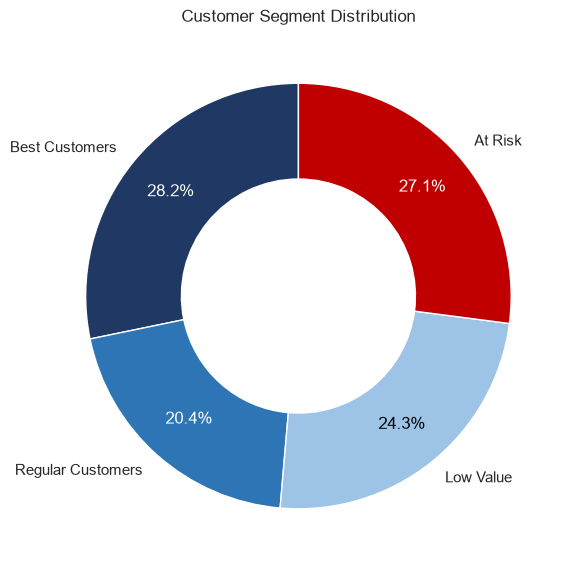

In [40]:
# Task 3: donut chart of the segment distribution
counts = clean['Segment'].value_counts().loc[order]
plt.figure(figsize=(6,6))
wedges,texts,autotexts = plt.pie(counts, labels=counts.index, autopct='%1.1f%%', pctdistance=0.775, startangle=90, colors=['#1F3864','#2E75B6','#9DC3E6','#C00000'], wedgeprops={'width':0.45,'edgecolor':'white'})
[t.set_color('white') for t in autotexts]
autotexts[2].set_color('black')
plt.title('Customer Segment Distribution')
plt.tight_layout();plt.savefig('../images/05_segment_donut.png');plt.show()

## 7. Key insights (generated from the data)

In [41]:
best=seg.loc['Best Customers']
r_rec=clean['Last_Purchase_Days_Ago'].corr(clean['Total_Spend']);r_ord=clean['Total_Orders'].corr(clean['Total_Spend'])
ch=clean.groupby('Acquisition_Channel')['Total_Spend'].mean()
print(f"1. {len(clean)} customers generated total revenue of Rs. {clean['Total_Spend'].sum():,.0f}; average spend per customer Rs. {clean['Total_Spend'].mean():,.0f}.")
print(f"2. Best Customers are {best['Pct_Customers']}% of customers but bring {best['Pct_Revenue']}% of revenue.")
print(f"3. Days since last purchase vs spend correlation = {r_rec:.2f}; number of orders vs spend = {r_ord:.2f}.")
print(f"4. Acquisition channel with highest average spend: {ch.idxmax()}; lowest: {ch.idxmin()}.")
print(f"5. {len(risk)} customers are At Risk; they have not bought for {risk['Last_Purchase_Days_Ago'].mean():.0f} days on average.")
print(f"6. Discount share vs spend correlation = {clean['Discount_Orders_Pct'].corr(clean['Total_Spend']):.2f} (very weak): heavy discount use does not mean higher spend.")

1. 255 customers generated total revenue of Rs. 2,889,354; average spend per customer Rs. 11,331.
2. Best Customers are 28.2% of customers but bring 73.7% of revenue.
3. Days since last purchase vs spend correlation = -0.24; number of orders vs spend = 0.72.
4. Acquisition channel with highest average spend: Referral; lowest: Email.
5. 69 customers are At Risk; they have not bought for 156 days on average.
6. Discount share vs spend correlation = -0.06 (very weak): heavy discount use does not mean higher spend.


## 8. Recommendations
- Reward **Best Customers** with loyalty points and early access to sales.
- Send **win-back offers** (email/SMS discount) to At Risk customers.
- Offer **bundle deals** to Regular Customers to raise their order value.
- Run **low-cost offers** for Low Value customers to encourage more orders.

> **Remember:** correlation does not prove causation. This analysis shows association, not cause.

## 9. Save the cleaned data

In [42]:
clean.to_csv('../data/processed/ecommerce_customers_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 255 rows
